# Прогноз выполнения заявки: CatBoost, важность признаков и SHAP

In [102]:
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, accuracy_score
import matplotlib.pyplot as plt
import shap
import numpy as np
from sklearn.preprocessing import OneHotEncoder

1. Подобрать модель CatBoost для предсказания вероятности выполнения погрузки. 
    - one_hot_max_size
    - bagging_temperature
    - num_trees

In [79]:
df = pd.read_excel('../data/orders.xlsx')

df = df[(df['Контрибуция'] > -60000000) & 
        (df['Среднее время между редакциями'] >= 0)]

df_rule = df['Дата отправления'] >= '2023-09-01'

categorial = [
    'Оператор',
    'Учетное направление',
    'Кластер назначения',
    'Кластер отправления',
]

df.drop([
    'Unnamed: 0',
    'Идентификатор погрузки',
    'Дата редактирования', 
    'Дата отправления', 
    'Дата отправления факт', 
    'Количество редакций после отправки',
    'Длительность афтершока', 
    'Код назначения', 
    'Код отправления', 
    'Идентификатор переноса'
], axis=1, inplace=True)

numerical = [
    'версия погрузки', 
    'Количество вагонов', 
    'Контрибуция', 
    'Длительность жизни', 
    'Время до отправки',
    'Количество отмен', 
    'Количество переносов',
    'Среднее время между редакциями'
]

X_train = df[~df_rule].drop('Результат', axis=1)
y_train = df.loc[~df_rule, 'Результат']

X_test = df[df_rule].drop('Результат', axis=1)
y_test = df.loc[df_rule, 'Результат']

In [80]:
model = CatBoostClassifier(
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=123,
    verbose=True
)

param_grid = {
    'iterations': [100, 300, 500],          
    'one_hot_max_size': [3, 5, 10],
    'bagging_temperature': [0, 1, 3, 5]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    n_jobs=-1
)

grid.fit(
    X_train,
    y_train,
    cat_features=categorial
)

Learning rate set to 0.110794
0:	total: 59.2ms	remaining: 5.86s
1:	total: 61ms	remaining: 2.99s
2:	total: 67.2ms	remaining: 2.17s
3:	total: 69.7ms	remaining: 1.67s
... (вывод сокращён: 17441 строк) ...
486:	total: 948ms	remaining: 25.3ms
487:	total: 950ms	remaining: 23.4ms
488:	total: 952ms	remaining: 21.4ms
489:	total: 954ms	remaining: 19.5ms
490:	total: 956ms	remaining: 17.5ms
491:	total: 958ms	remaining: 15.6ms
492:	total: 960ms	remaining: 13.6ms
493:	total: 961ms	remaining: 11.7ms
494:	total: 963ms	remaining: 9.73ms
495:	total: 965ms	remaining: 7.78ms
496:	total: 967ms	remaining: 5.83ms
497:	total: 968ms	remaining: 3.89ms
498:	total: 970ms	remaining: 1.94ms
499:	total: 972ms	remaining: 0us


GridSearchCV(cv=3,
             estimator=<catboost.core.CatBoostClassifier object at 0x138f15100>,
             n_jobs=-1,
             param_grid={'bagging_temperature': [0, 1, 3, 5],
                         'iterations': [100, 300, 500],
                         'one_hot_max_size': [3, 5, 10]},
             scoring='roc_auc')

In [81]:
print("Лучшие параметры:", grid.best_params_)
print("Лучший ROC-AUC:", grid.best_score_)

Лучшие параметры: {'bagging_temperature': 0, 'iterations': 500, 'one_hot_max_size': 3}
Лучший ROC-AUC: 0.836692998921514


In [82]:
best_model = grid.best_estimator_

proba = best_model.predict_proba(X_test)[:, 1]
preds = best_model.predict(X_test)

roc_auc = roc_auc_score(y_test, proba)
acc = accuracy_score(y_test, preds)

In [83]:
print("ROC-AUC на test:", roc_auc)
print("Точность на test:", acc)

ROC-AUC на test: 0.7945688342451076
Точность на test: 0.710594315245478


2. Оценить важность признаков.

In [86]:
feature_importance = best_model.get_feature_importance()

fi = pd.DataFrame({
    "Признак": X_train.columns,
    "Важность": feature_importance
}).sort_values("Важность", ascending=False)

fi

,Признак,Важность
9,Количество отмен,23.741207
8,Время до отправки,15.951181
1,Оператор,10.225310
0,версия погрузки,10.011125
3,Кластер назначения,7.872190
2,Учетное направление,6.561551
11,Среднее время между редакциями,6.029854
4,Кластер отправления,4.910062
10,Количество переносов,4.855969
6,Контрибуция,3.877463


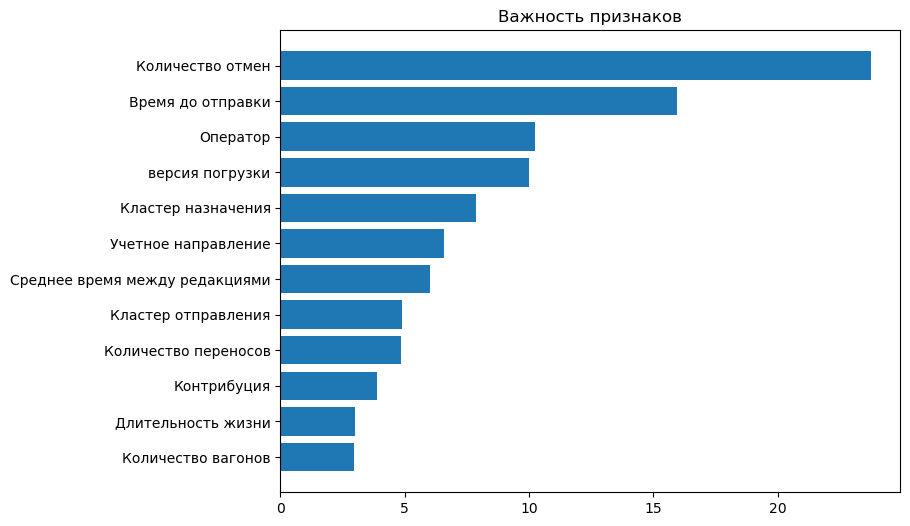

In [88]:
fi_sorted = fi.sort_values("Важность")

plt.figure(figsize=(8,6))
plt.barh(fi_sorted["Признак"], fi_sorted["Важность"])
plt.title("Важность признаков")
plt.show()

3. Оценить важность объектов.

In [98]:
explainer = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(X_test)

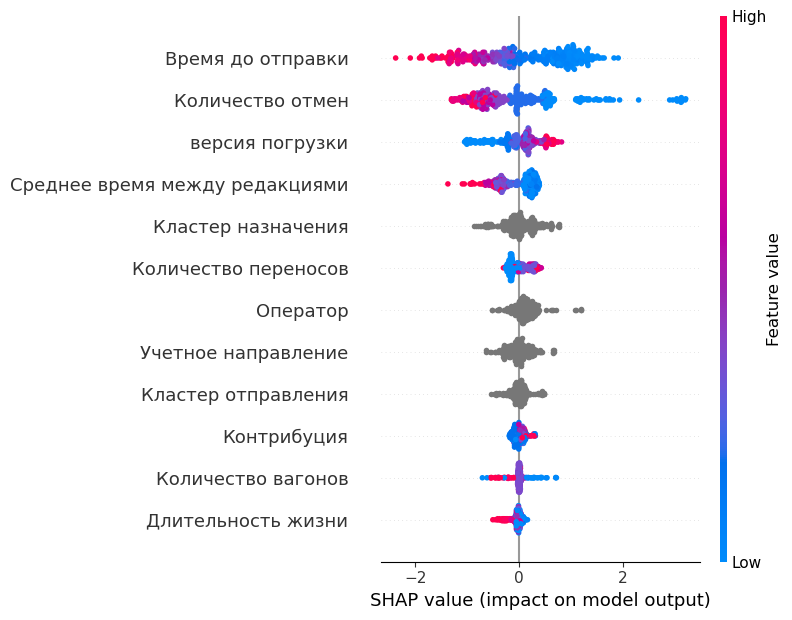

In [96]:
shap.summary_plot(shap_values, X_test)

5. Реализовать dash интерфейс, который выведет построенные деревья.

In [111]:
import dash
from dash import dcc, html, Input, Output
import base64
import io

app = dash.Dash(__name__)

n_trees = best_model.tree_count_

app.layout = html.Div([
    html.H2("Визуализация деревьев CatBoost"),

    dcc.Dropdown(
        id="tree-dropdown",
        options=[{"label": f"Tree {i}", "value": i} for i in range(n_trees)],
        value=0
    ),

    html.Img(id="tree-plot")
])


@app.callback(
    Output("tree-plot", "src"),
    Input("tree-dropdown", "value")
)
def update_tree(tree_index):

    fig = best_model.plot_tree(tree_index)

    buf = io.BytesIO()
    fig.savefig(buf, format="png")
    buf.seek(0)

    encoded = base64.b64encode(buf.read()).decode()

    plt.close(fig)

    return f"data:image/png;base64,{encoded}"


if __name__ == "__main__":
    app.run(mode='inline', port=8062, debug=True)